# Header: Forward modeling of the HT-ATES site (version 3)

**This code is based on the EASYGO summer school exercises: https://github.com/emsig/easygo-training-em/blob/main/emg3d_ATES.ipynb**

Goals:
- test the receiver line result for different sources suggested in the old survey design, survey design 1

Assumptions:
- we use the coarse grid and fine grid from FWMv2

# Code

In [1]:
import emg3d
import empymod
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from Emg3d_extra_grid_functions_v26 import *
import pandas as pd

plt.style.use('bmh')

# Comment this out on Google Colab
#%matplotlib widget

## Construct survey, grid and baseline model

- We use a fine grid (3 x finer in the center) with same cell alignment as the inversion grid
- Source and receiver are 200 m away (y_s=-126 and y_r=74)
- Depth is negative!

In [2]:
# Source
source = [0, -126, 0, 90.0, 0] # y-directed point dipole on the surface

#from the inversion script for survey design 1
src_coords = [(0, -126, 0, 90.0, 0.0),
              (0, -25, 0, 90.0, 0.0),
              (0, 25, 0, 90.0, 0.0),
              (0, 100, 0, 90.0, 0.0),
              (-75, -50, 0, 0.0, 0.0),
              (-75, 50, 0, 0.0, 0.0),
              (-25, 50, 0, 0.0, 0.0),
              (25, 50, 0, 0.0, 0.0),
              (75, -50, 0, 0.0, 0.0),
              (75, 50, 0, 0.0, 0.0)]
src = []
for src_coord in src_coords:
    src.append(emg3d.surveys.txrx_coordinates_to_dict(emg3d.TxElectricDipole, src_coord))

# Source frequency
frequency = 1

# Receiver offsets
offsets = np.arange(0, 300, 7.5)  # 300 m long receiver line

# receiver-array: x, y, z, azimuth, dip
receivers = (offsets*0, [74]*len(offsets), -offsets, 0, 90)  # z-directed, Ez response

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -50, -80, -120, -190]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 52.0, 38.0, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)


In [3]:
# define the input that stays the same for all models
inp = {
    'src': src,
    'rec': receivers,
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
}

## Define scenario to test

In [4]:
#load custom plumes from Excel file

df_loaded = pd.read_excel('Sept2026_plumes.xlsx', sheet_name=None, usecols="B:G", skiprows=1)

keys = df_loaded.keys()
print("Plume templates loaded : ", keys)
print("Dimensions of template : ", np.shape(df_loaded[list(keys)[0]].to_numpy())) #This should give (6,6)

Plume templates loaded :  dict_keys(['Cyl1', 'Cyl2', 'Boy1', 'Boy2', 'Lat1-0', 'Lat1-1', 'Lat1-2', 'Lat2-0', 'Lat2-1', 'Lat2-2'])
Dimensions of template :  (6, 6)


In [5]:
#QC

df_loaded['Cyl2']

,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,4,4,3,2,1,1
1,4,4,3,2,1,1
2,4,4,3,2,1,1
3,4,4,3,2,1,1
4,4,4,3,2,1,1
5,4,4,3,2,1,1


In [6]:
#Determine equivalent temperatures

m = 0.02
rho_orig = 29.5
T_orig = 14
T_ref = 20

def find_rho_ref(m, T_orig, rho_orig):
    rho_ref = (1+m*(T_orig-T_ref))*rho_orig
    return rho_ref

print(find_rho_ref(m, T_orig, rho_orig))

rho_ref = 25.96

def convert_T_to_rho(m, T):
    rho = rho_ref/(1+m*(T-T_ref))
    return rho

def convert_rho_to_T(m, rho):
    #rho*(1+m(...))=rho_ref
    #rho_ref-rho = rho*m*(...)
    #(rho_ref-rho)/(rho*m) = T-T_ref
    T = (rho_ref-rho)/(rho*m)+T_ref
    return T

print(convert_rho_to_T(m, 25))
print(convert_rho_to_T(m, 20))
print(convert_rho_to_T(m, 14))


25.96
21.92
34.900000000000006
62.714285714285715


In [7]:
#INPUTS

# How to interpret template values
res_0 = resistivities_base[4]
res_1 = resistivities_base[4]
res_2 = 25
res_3 = 20
res_4 = 14
res_dict = {'0': res_0, '1': res_1, '2': res_2, '3': res_3, '4': res_4}

# How to locate the cells from the template on the grid
r_spacing = 15 #Assuming always that we start from the origin
z_min = -190
z_max = -120
z_spacing = 70/6

# Template to use
key = 'Cyl1'

# Reformat and pad with original aquifer values (for radius which expands further than r_max)
template = np.flip(df_loaded[key].to_numpy(), axis=0)
template_padded = np.ones((10,10), dtype=str)
template_padded[:6, :6] = template
template = template_padded

## Simulations using coarse grid

### Create grid

In [8]:
grid = emg3d.construct_mesh(
    center=(0,0,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-100, 100], [-140, 100], [-300, 25]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [15, 15, 5],
)
 
grid # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 524,288 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     64   -102,353.92    102,353.92     15.00 26,438.88    1.35
   y     64   -102,493.09    142,269.02     15.00 39,820.93    1.39
   z    128   -108,798.04    143,051.73      5.00 34,528.69    1.32

### Insert baseline values into grid

In [9]:
#Insert resistivity values into the grid

# Pre-allocate an array with number of cells corresponding to our grid
res_base = np.ones(grid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    res_base[:, :, (grid.cell_centers_z > dd[i+1]) & (grid.cell_centers_z <= dd[i])] = resistivities_base[i]

model_base = emg3d.Model(grid, property_x=res_base, mapping='Resistivity')

### Insert plume values into grid

In [10]:
# Insert the plume according to the template

# Find indeces of the place to insert the plume
ix_min, iy_min, iz_min, ix_max, iy_max, iz_max = find_cuboid_indeces_xyz(grid, x_extent = 100, y_extent=100, zmin = z_min, zmax = z_max)

radii = []
# Go through each cell in the volume and adapt resistivity to the corresponding template value
res_target = res_base.copy()
for ix in np.arange(ix_min, ix_max+1):
    for iy in np.arange(iy_min, iy_max+1):
        for iz in np.arange(iz_min, iz_max+1):
            grid_loc = [grid.cell_centers_x[ix], grid.cell_centers_y[iy], grid.cell_centers_z[iz]]
            radius = np.sqrt(grid_loc[0]**2+grid_loc[1]**2)
            temp_ir = int(radius/r_spacing) #int rounds to the integer; this makes sure that the index chooses the innermost cell
            temp_iz = int(-(z_min-grid_loc[2])/z_spacing) #int rounds to the integer; this makes sure that the index chooses the topmost cell
            res_target[ix, iy, iz] = res_dict[str(template[temp_iz, temp_ir])]

[-99, -99, -189] [99, 99, -121]
x:  -97.50000000000777
y:  -97.49999999999955
z:  -187.49999999999397
x:  97.49999999999223
y:  97.50000000000045
z:  -122.49999999999397


In [11]:
model_target = emg3d.Model(grid, property_x=res_target, mapping='Resistivity')

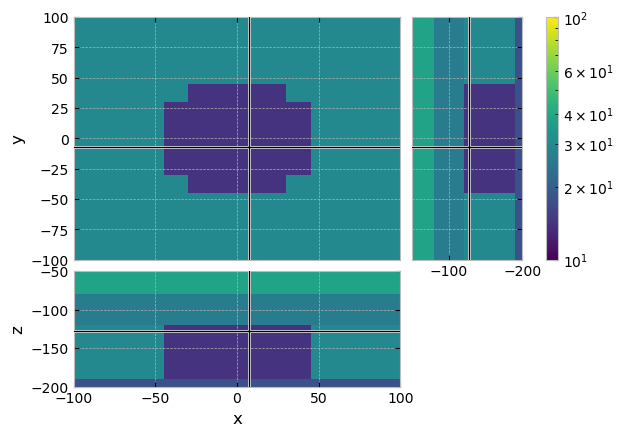

In [12]:
#QC cube location

grid.plot_3d_slicer(
    model_target.property_x,
    pcolor_opts={'norm': LogNorm(vmin=1e1, vmax=1e2)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -50],
    zslice=-125,
)
fig = plt.gcf()

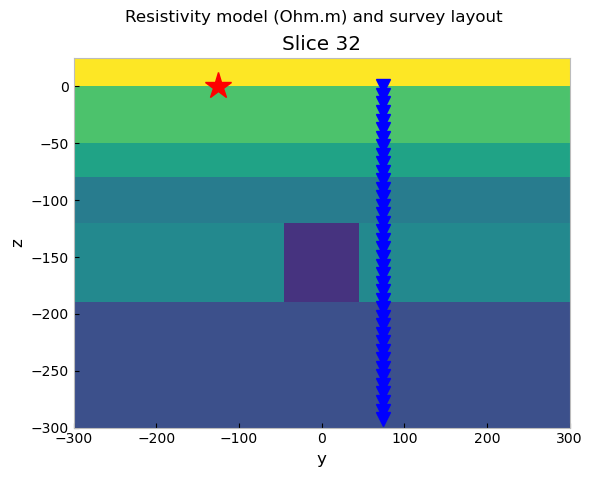

In [13]:
#Focus on the y,z plane
grid.plot_slice(
    model_target.property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(receivers[1], receivers[2], 'bv', markersize = 10)
axs[1].plot(source[1], source[2], 'r*', markersize = 20)
axs[1].grid(False)

### Emg3d simulations

In [14]:
empymod_base_list = []

for i in np.arange(len(src_coords)):
    inp['src'] = src_coords[i]
    empymod_base_list.append(empymod.bipole(res=resistivities_base, **inp))

In [15]:
#Generate source field

source_field_list = []
for i in np.arange(len(src_coords)):
    source = src_coords[i]
    source_field_list.append(emg3d.fields.get_source_field(grid, source=source, frequency=frequency))

In [16]:
# Baseline model

emg3d_field_base_list = []
for i in np.arange(len(src_coords)):
    sfield = source_field_list[i]
    emg3d_field_base_list.append(emg3d.solve(model_base, sfield, verb=2))

:: emg3d :: 6.7e-07; 3(18); 0:04:16; CONVERGED
:: emg3d :: 8.2e-07; 2(15); 0:01:58; CONVERGED
:: emg3d :: 8.4e-07; 3(17); 0:02:11; CONVERGED
:: emg3d :: 6.5e-07; 4(20); 0:02:46; CONVERGED
:: emg3d :: 5.2e-07; 4(20); 0:02:39; CONVERGED
:: emg3d :: 5.6e-07; 4(20); 0:02:43; CONVERGED
:: emg3d :: 4.9e-07; 3(19); 0:02:33; CONVERGED
:: emg3d :: 5.3e-07; 3(19); 0:02:13; CONVERGED
:: emg3d :: 5.3e-07; 4(20); 0:02:19; CONVERGED
:: emg3d :: 5.8e-07; 4(20); 0:02:22; CONVERGED


In [17]:
# Get receiver line response

emg3d_line_base_list = []
for i in np.arange(len(src_coords)):
    efield = emg3d_field_base_list[i]
    emg3d_line_base_list.append(efield.get_receiver(receivers, 'linear'))

In [18]:
# Solve with target

emg3d_field_target_list = []
for i in np.arange(len(src_coords)):
    sfield = source_field_list[i]
    emg3d_field_target_list.append(emg3d.solve(model_target, sfield, verb=2))

:: emg3d :: 7.0e-07; 3(18); 0:02:03; CONVERGED
:: emg3d :: 9.5e-07; 2(15); 0:01:42; CONVERGED
:: emg3d :: 8.4e-07; 3(17); 0:01:58; CONVERGED
:: emg3d :: 6.8e-07; 4(20); 0:02:20; CONVERGED
:: emg3d :: 6.2e-07; 4(20); 0:02:24; CONVERGED
:: emg3d :: 6.9e-07; 4(20); 0:02:18; CONVERGED
:: emg3d :: 5.0e-07; 3(19); 0:02:09; CONVERGED
:: emg3d :: 5.4e-07; 3(19); 0:02:17; CONVERGED
:: emg3d :: 6.3e-07; 4(20); 11:40:43; CONVERGED
:: emg3d :: 7.1e-07; 4(20); 0:06:10; CONVERGED


In [20]:
# Get receiver line response

emg3d_line_target_list = []
for i in np.arange(len(src_coords)):
    efield = emg3d_field_target_list[i]
    emg3d_line_target_list.append(efield.get_receiver(receivers, 'linear'))

### Plots

In [21]:
plt.rcParams["font.size"] = 12

(179.5, 180.0)

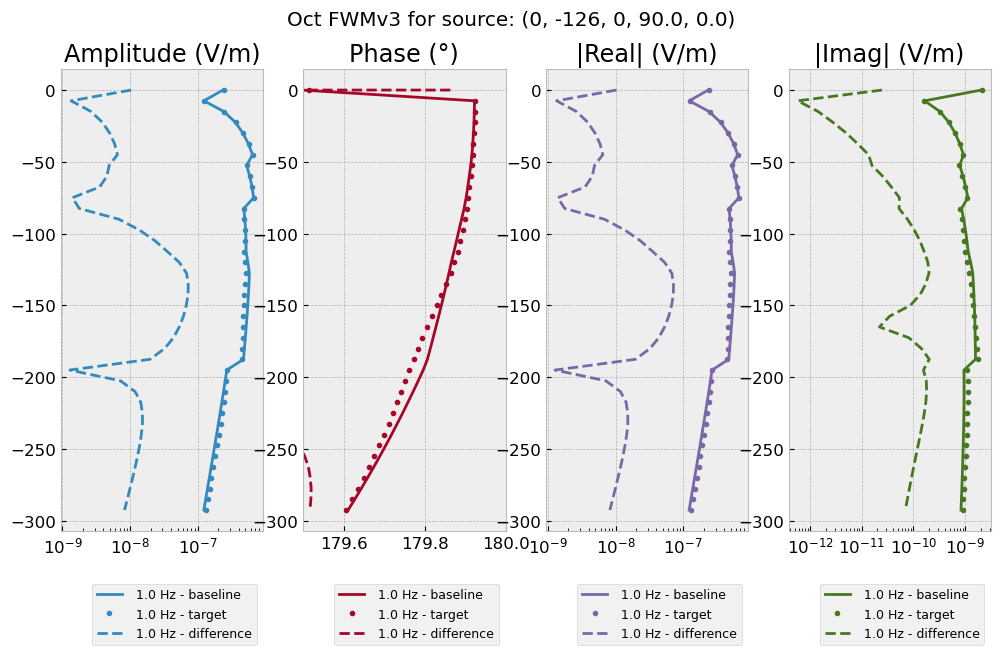

In [22]:
src_nr = 0

# QC data
#data_empymod = empymod_base_list[src_nr]
base3d = emg3d_line_base_list[src_nr]
target3d = emg3d_line_target_list[src_nr]
diff3d = emg3d_line_target_list[src_nr] - emg3d_line_base_list[src_nr]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6))#, tight_layout=True)
axes = [ax2, ax3, ax4, ax5]

plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
p_base = [np.abs(base3d), np.angle(base3d,deg=True), abs(base3d.real), abs(base3d.imag)]
p_target= [np.abs(target3d), np.angle(target3d,deg=True), abs(target3d.real), abs(target3d.imag)]
p_diff = [np.abs(diff3d), np.angle(diff3d,deg=True), abs(diff3d.real), abs(diff3d.imag)]
fig.suptitle("Oct FWMv3 for source: " +str(src_coords[src_nr]))
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(p_base[j][:], receivers[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - baseline")
    ax.plot(p_target[j][:], receivers[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - target")
    ax.plot(p_diff[j][:], receivers[2], 'C'+str(j)+'--', label=f"{frequency: 2.1f} Hz - difference")
    ax.legend(bbox_to_anchor=(1,-0.1), fontsize=9)
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    #ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])

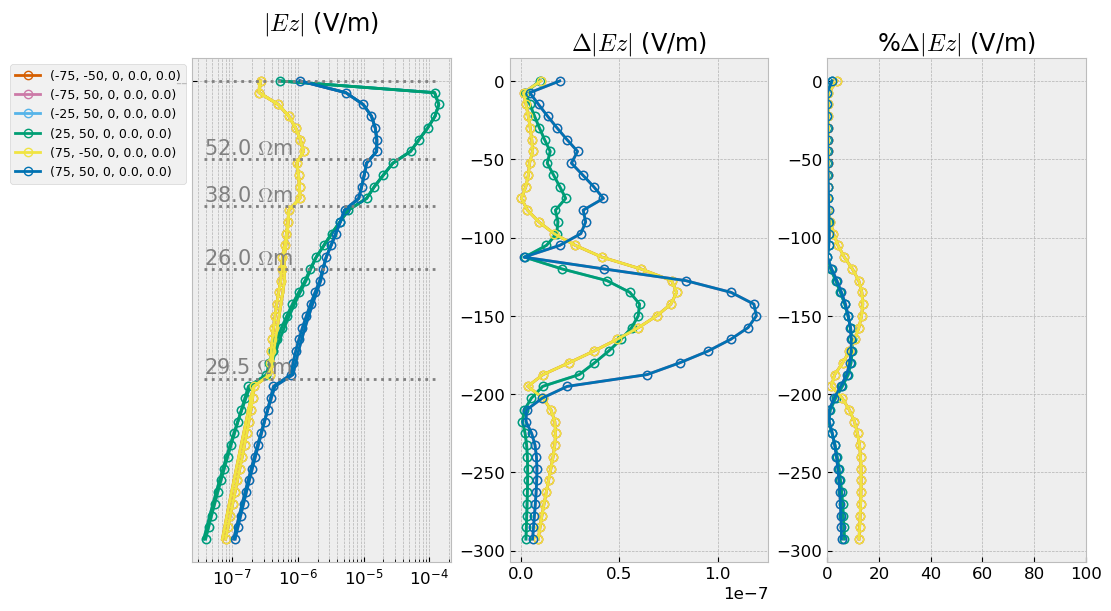

In [ ]:
# Plot differences only

src_nrs = np.arange(len(src_coords))[4:]

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

#fig3.suptitle("Baseline model vs cubic target model")
plt.rcParams["font.size"] = 12

ax31.set_title('$|Ez|$ (V/m)')
ax32.set_title('$\\Delta |Ez|$ (V/m)')
ax33.set_title('%$\\Delta |Ez|$ (V/m)')

for src_nr in src_nrs:

    base3d = emg3d_line_base_list[src_nr]
    target3d = emg3d_line_target_list[src_nr]
    diff3d = emg3d_line_target_list[src_nr] - emg3d_line_base_list[src_nr]

    ax31.plot(base3d.amp(), -offsets, 'C'+str(src_nr), '--', linewidth=2)
    ax31.plot(target3d.amp(), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', label = str(src_coords[src_nr]), linewidth=2) # scale your emg3d amplitues by the source length

    
    ax32.plot(np.abs(target3d.amp()-base3d.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)

    ax33.plot(100*np.abs((target3d.amp()-base3d.amp())/base3d.amp()), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 100])

ax31.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)
ax34.set_axis_off()

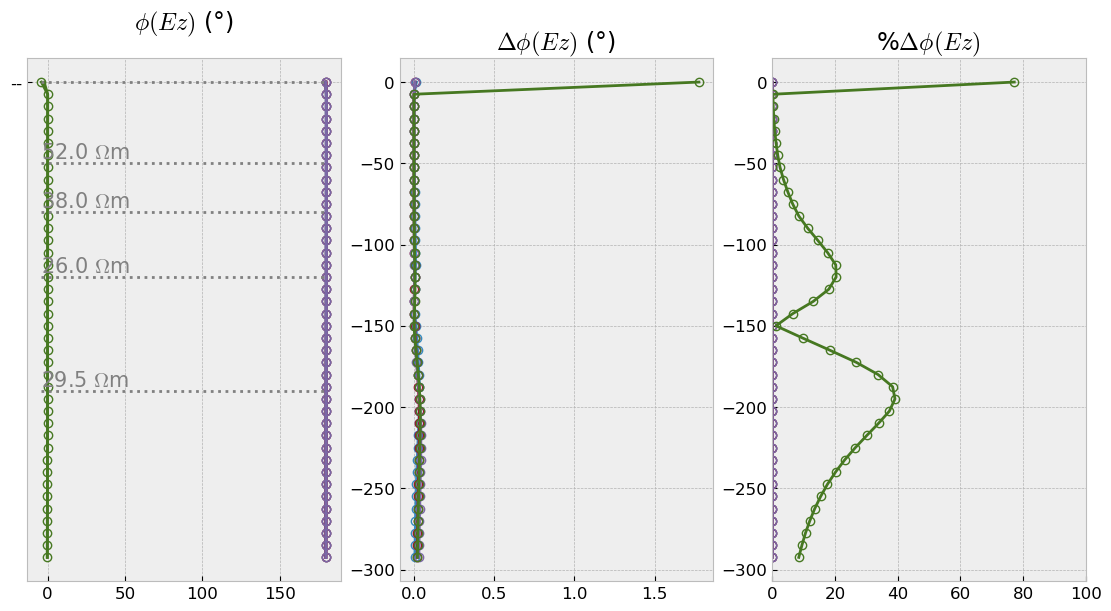

In [41]:
# Plot differences only

src_nrs = np.arange(len(src_coords))[:4]

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

#fig3.suptitle("Baseline model vs cubic target model")
plt.rcParams["font.size"] = 12

ax31.set_title('$\\phi(Ez)$ (°)')
ax32.set_title('$\\Delta \\phi(Ez)$ (°)')
ax33.set_title('%$\\Delta \\phi(Ez)$ ')

for src_nr in src_nrs:

    base3d = emg3d_line_base_list[src_nr]
    target3d = emg3d_line_target_list[src_nr]
    diff3d = emg3d_line_target_list[src_nr] - emg3d_line_base_list[src_nr]

    ax31.plot(base3d.pha(deg=True), -offsets, 'C'+str(src_nr), '--', linewidth=2)
    ax31.plot(target3d.pha(deg=True), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', label = str(src_coords[src_nr]), linewidth=2) # scale your emg3d amplitues by the source length
    
    ax32.plot(np.abs(target3d.pha(deg=True)-base3d.pha(deg=True)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)

    ax33.plot(100*np.abs((target3d.pha(deg=True)-base3d.pha(deg=True))/base3d.pha(deg=True)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 100])

#ax31.set_xlim([1e-7, 1e-6])
#ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)
ax34.set_axis_off()

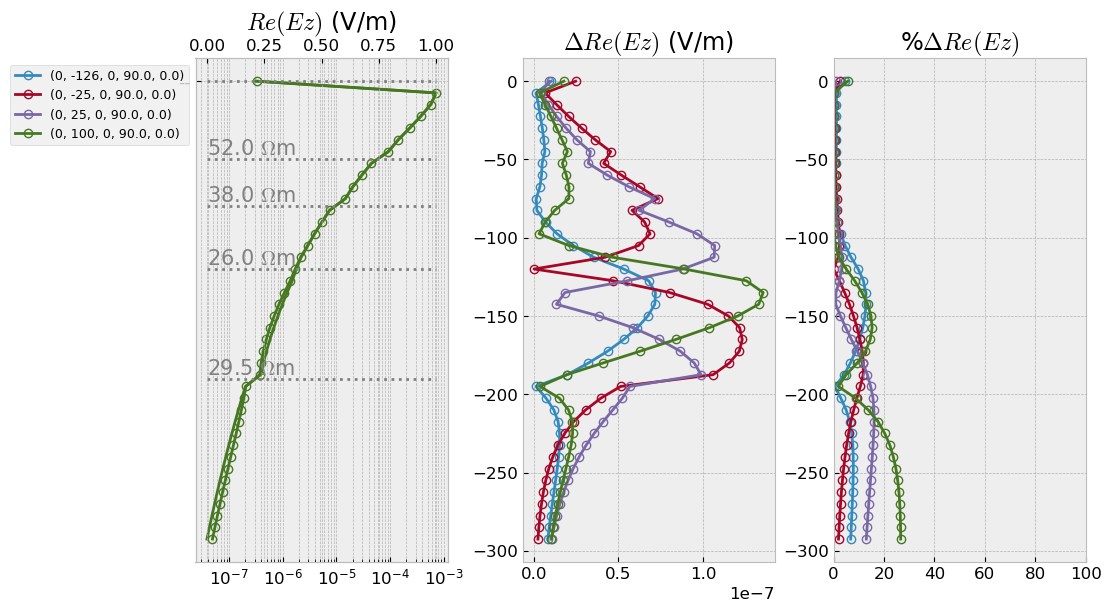

In [42]:
# Plot differences only

src_nrs = np.arange(len(src_coords))[:4]

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

#fig3.suptitle("Baseline model vs cubic target model")
plt.rcParams["font.size"] = 12

ax31.set_title('$Re(Ez)$ (V/m)')
ax32.set_title('$\\Delta Re(Ez)$ (V/m)')
ax33.set_title('%$\\Delta Re(Ez)$')

for src_nr in src_nrs:

    base3d = emg3d_line_base_list[src_nr]
    target3d = emg3d_line_target_list[src_nr]
    diff3d = emg3d_line_target_list[src_nr] - emg3d_line_base_list[src_nr]

    ax31.plot(np.real(base3d), -offsets, 'C'+str(src_nr), '--', linewidth=2)
    ax31.plot(np.real(target3d), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', label = str(src_coords[src_nr]), linewidth=2) # scale your emg3d amplitues by the source length

    
    ax32.plot(np.abs(np.real(target3d)-np.real(base3d)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)

    ax33.plot(100*np.abs((np.real(target3d)-np.real(base3d))/np.real(base3d)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 100])

ax31.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)

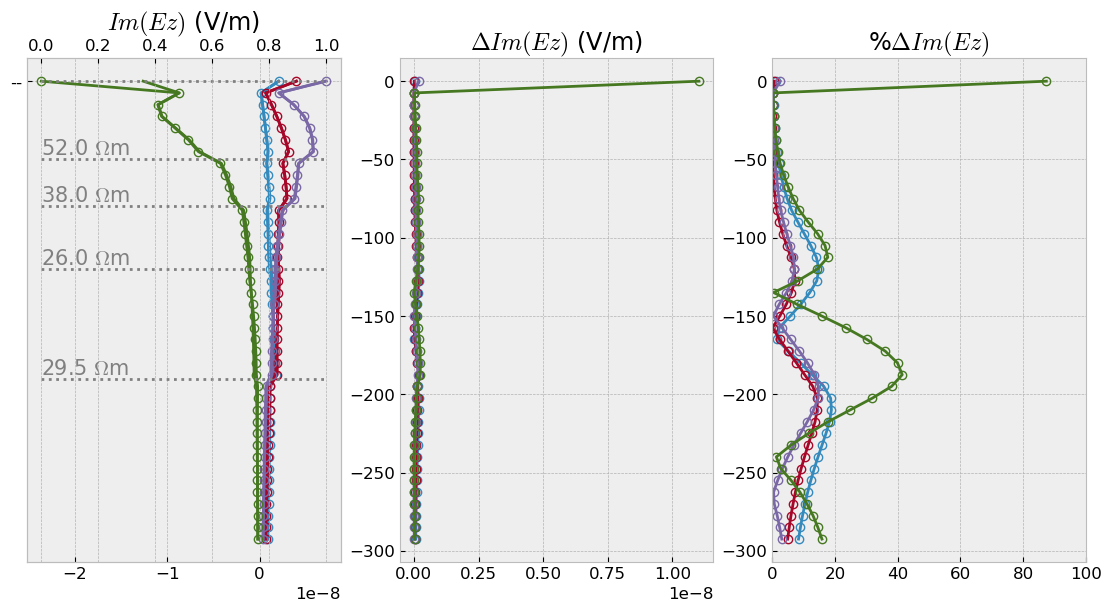

In [52]:
# Plot differences only

src_nrs = np.arange(len(src_coords))[:4]

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

#fig3.suptitle("Baseline model vs cubic target model")
plt.rcParams["font.size"] = 12

ax31.set_title('$Im(Ez)$ (V/m)')
ax32.set_title('$\\Delta Im(Ez)$ (V/m)')
ax33.set_title('%$\\Delta Im(Ez)$')

for src_nr in src_nrs:

    base3d = emg3d_line_base_list[src_nr]
    target3d = emg3d_line_target_list[src_nr]
    diff3d = emg3d_line_target_list[src_nr] - emg3d_line_base_list[src_nr]

    ax31.plot(np.imag(base3d), -offsets, 'C'+str(src_nr), '--', linewidth=2)
    ax31.plot(np.imag(target3d), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', label = str(src_coords[src_nr]), linewidth=2) # scale your emg3d amplitues by the source length
    #ax31.set_xlim([-0.3e-8, 0])
    
    ax32.plot(np.abs(np.imag(target3d)-np.imag(base3d)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    #ax32.set_xlim([0, 5e-10])

    ax33.plot(100*np.abs((np.imag(target3d)-np.imag(base3d))/np.imag(base3d)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 100])

#ax31.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
#ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)

In [ ]:
emg3d.Report()